# Notebook 03 - Análisis y modelado con diagnósticos CIE-10

## Objetivos
- Cargar y preparar datos de diagnósticos CIE-10 integrados con datos clínicos base.
- Implementar un pipeline de preprocesamiento con imputación, codificación ordinal y escalado.
- Realizar análisis exploratorio de la distribución de diagnósticos en cohortes de cáncer de pulmón.
- Aplicar tests estadísticos (Fisher exact) para identificar asociaciones significativas entre diagnósticos y el target.
- Entrenar y evaluar múltiples modelos (RandomForest, SVM, XGBoost, MLP) con validación cruzada.
- Generar métricas de desempeño y reportes comparativos en el conjunto test.

## Resumen de secciones y celdas

| Sección | Objetivo | Celdas (aprox.) |
|---|---|---|
| Carga de librerías y datos | Inicializar entorno, cargar datasets CIE-10 y crear target | 2-4 |
| Definición de datos | Cargar datos de diagnósticos CIE-10 y exploración inicial | 5-8 |
| División train/test | Partición estratificada de datos diagnósticos | 9 |
| Pipeline de preprocesamiento | Imputación, codificación ordinal y escalado de variables | 10-12 |
| Análisis exploratorio visual | Distribución de diagnósticos en cohorte test | 13-15 |
| Análisis exploratorio avanzado | Distribución condicional por presencia/ausencia de cáncer | 16-17 |
| Patrones clínicos | Identificación de diagnósticos con mayor prevalencia diferencial | 18 |
| Fundamento estadístico | Marco teórico para análisis de asociaciones (Bernoulli, probabilidades) | 19-20 |
| Test de Fisher y Odds Ratio | Cálculo de asociaciones estadísticas entre diagnósticos y cáncer | 21-22 |
| Tablas de contingencia | Desagregación de asociaciones por código CIE | 23 |
| Modelado con CV | Búsqueda de hiperparámetros multmodelo con validación cruzada | 24-30 |
| Reporte de rendimiento | Evaluación final en datos test con métricas agregadas | 31-32 |


In [3]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegressionCV
from sklearn.inspection import permutation_importance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

from joblib import Memory
import joblib
import os
import tempfile
import shutil

In [7]:
import importlib
import sys
if 'funciones' in sys.modules:
    importlib.reload(sys.modules['funciones'])
from funciones import tunear_multiples_modelos, resumen_tuning

## Definición de los datos

Vamos a definir la raíz del proyecto y evitar rutas absolutas.

In [8]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")

DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


In [9]:
datos = pd.read_csv(DATA_DIR/"synthea_30k.csv", low_memory=False)
y=datos['label']

In [10]:
datos_cie = pd.read_csv(DATA_DIR/"cie_diagnosticos.csv", low_memory=False)
datos_cie.set_index("ptnum", inplace=True)
datos_cie = datos_cie.astype(object)

In [11]:
datos_cie.head()

,CIE10_A41.0,CIE10_A41.5,CIE10_A41.9,CIE10_A49.9,CIE10_B34.9,CIE10_B96.2,CIE10_C18.8,CIE10_C18.9,CIE10_C50.9,CIE10_C78.5,...,CIE10_Z35.9,CIE10_Z59.0,CIE10_Z60.4,CIE10_Z65.5,CIE10_Z72.0,CIE10_Z73.3,CIE10_Z86.7,CIE10_Z89.1,CIE10_Z89.4,CIE10_Z89.6
ptnum,,,,,,,,,,,,,,,,,,,,,
p15865,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,...,NaN,NaN,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN
p27452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
p12382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN
p21814,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN
p2902,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,...,NaN,NaN,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN


El procesamiento de los datos será muy parecida a la lógica que usamos en los códigos de SNOMED CT. Los NaN representan ausencia de la enfermedad por lo que imputaremos todos sus valores a 0 mientras que los valores 1 representan la presencia del diagnóstico en algún punto del historial médico del paciente correspondiente.

In [12]:
datos_cie.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4221 entries, p15865 to p9822
Columns: 156 entries, CIE10_A41.0 to CIE10_Z89.6
dtypes: object(156)
memory usage: 5.1+ MB


## División de los datos en train y test

In [11]:
X_train_cie, X_test_cie, y_train_cie, y_test_cie = train_test_split(datos_cie,y, test_size=0.2, random_state=625, stratify=y)

## Pipeline de preprocesamiento

In [6]:
from sklearn import set_config

set_config(transform_output="pandas")
from sklearn.preprocessing import FunctionTransformer

def to_int_types(df):
    return df.astype(int)

cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="constant", fill_value=0.0,keep_empty_features=True)),
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ("to_int", FunctionTransformer(to_int_types))
])

num_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(strategy='constant', fill_value=0.0))
])

preprocesamiento_cie = ColumnTransformer([
    ("cat", cat_pipeline, make_column_selector(dtype_include="object")),
    ("num", num_pipeline, make_column_selector(dtype_include="float64"))
], remainder="passthrough"
 , verbose_feature_names_out=False)

seleccion_EDA = Pipeline([
    ("preprocesamiento", preprocesamiento_cie),
    ("50mejores", SelectKBest(k=25)),
])

In [14]:
X_train_cie_proc = seleccion_EDA.fit_transform(X_train_cie, y_train_cie)
X_test_cie_proc = seleccion_EDA.transform(X_test_cie)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [  0   1  20  41  74 153 155] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


## Análisis exploratorio de diagnósticos

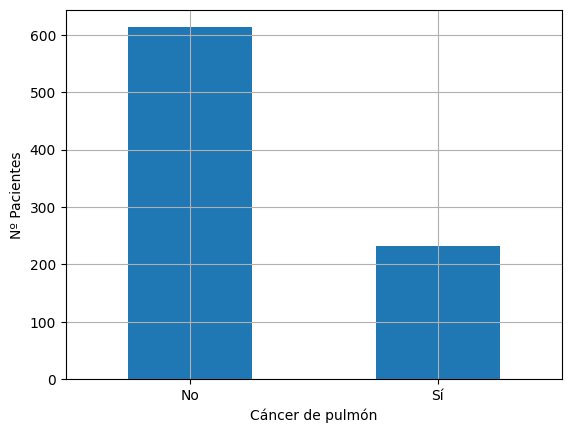

In [17]:
ax = y_test_cie.value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Cáncer de pulmón")
plt.ylabel("Nº Pacientes")
# Cambiar etiquetas: 0 -> "No", 1 -> "Sí"
ax.set_xticklabels(['No', 'Sí'])
plt.show()

In [18]:
X_test_cie_proc

,CIE10_D64.9,CIE10_E11.9,CIE10_E14.2,CIE10_E66.9,CIE10_E78.1,CIE10_E78.5,CIE10_E88.8,CIE10_G30.9,CIE10_H36.0,CIE10_I50.0,...,CIE10_M54.2,CIE10_M54.5,CIE10_N08.3,CIE10_N18.1,CIE10_O03.9,CIE10_R50.9,CIE10_R73.9,CIE10_T74.9,CIE10_U07.1,CIE10_Z60.4
ptnum,,,,,,,,,,,,,,,,,,,,,
p13554,0,0,0,0,0,0,0,0,0,0,...,1,1,0,0,0,0,0,0,0,1
p13837,0,0,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
p16413,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,1,1,1
p10432,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
p18646,1,0,0,0,0,1,0,0,0,1,...,1,1,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p28414,1,1,1,0,1,1,1,0,1,0,...,1,1,1,1,0,0,1,1,0,1
p9116,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,1,0,1
p21230,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


C:\Users\rtrin\AppData\Local\Temp\ipykernel_9900\4212235094.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=X_test_cie_proc[col], ax=axes[i], stat="percent", palette="mako")
C:\Users\rtrin\AppData\Local\Temp\ipykernel_9900\4212235094.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['Ausente (0)' if label == '0' else 'Presente (1)' for label in labels])
C:\Users\rtrin\AppData\Local\Temp\ipykernel_9900\4212235094.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=X_test_cie_proc[col], ax=axes[i], stat="percent", palette="mako")
C:\Users\rtrin\AppData\Local\Temp\ipyk

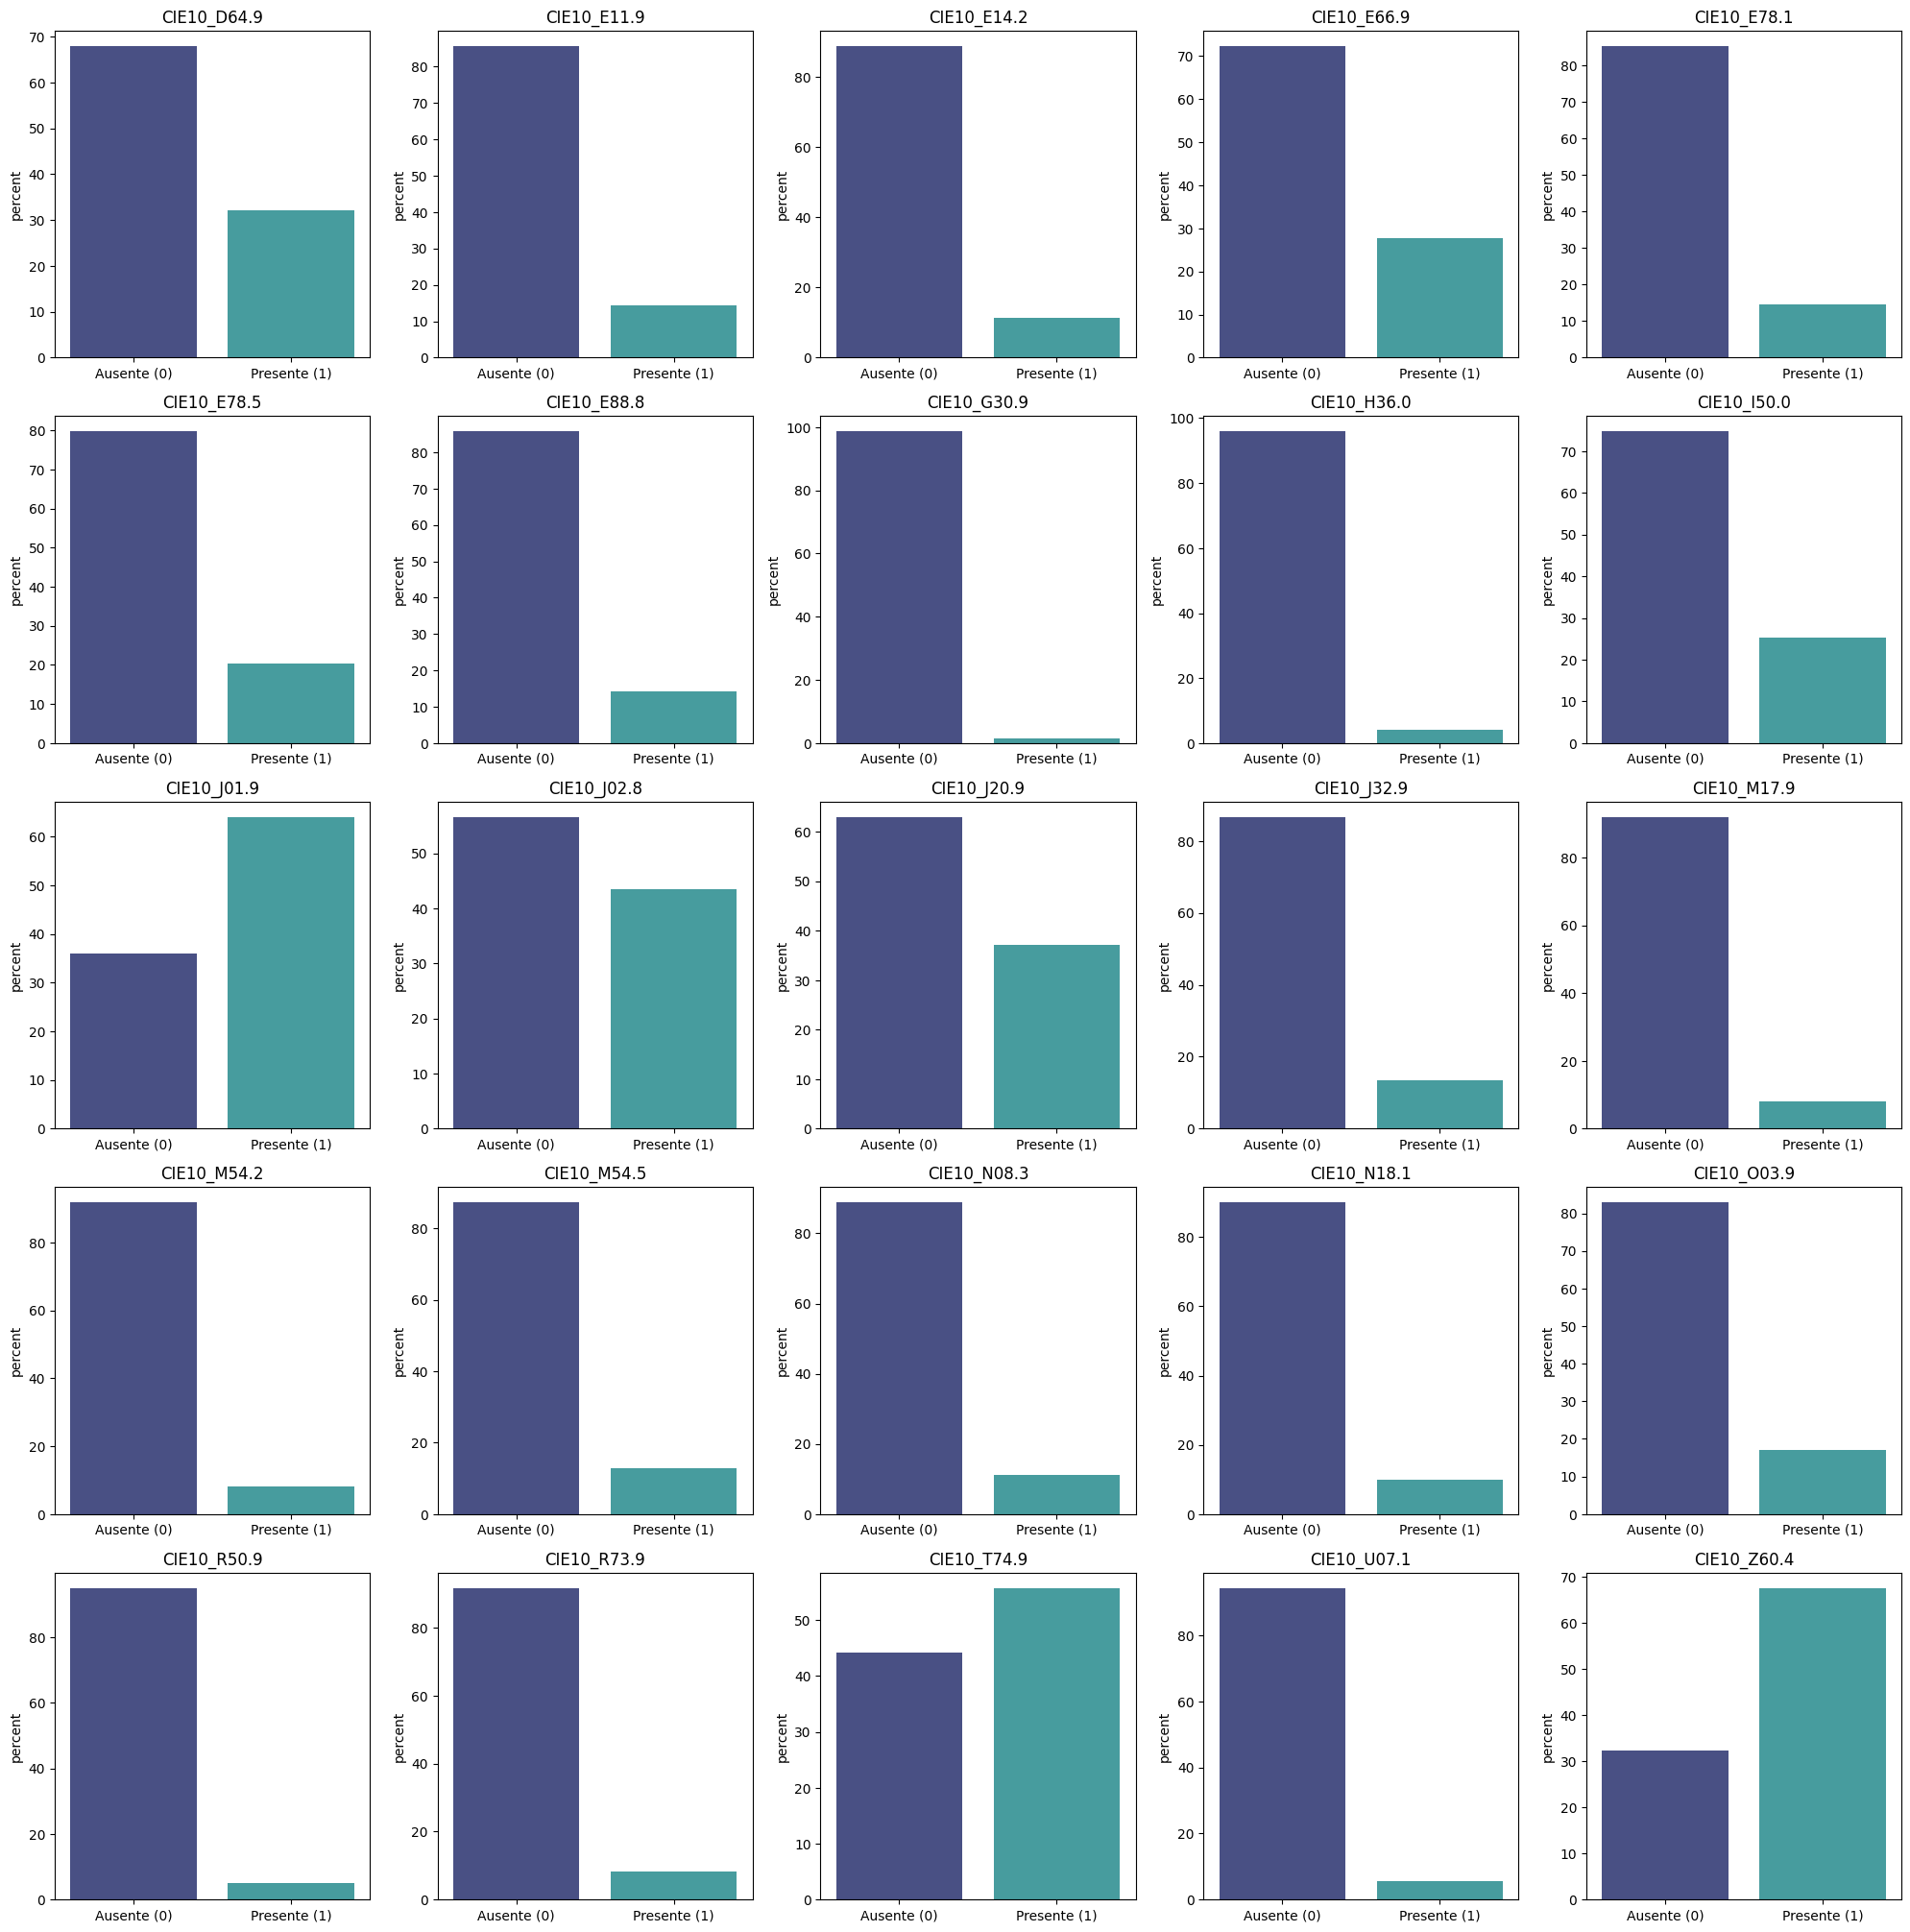

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = X_test_cie_proc.columns
n_cols = 5
n_rows = (len(cols) // n_cols) + 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(x=X_test_cie_proc[col], ax=axes[i], stat="percent", palette="mako")
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    # Cambiar etiquetas: 0 -> "No", 1 -> "Sí"
    labels = [label.get_text() for label in axes[i].get_xticklabels()]
    axes[i].set_xticklabels(['Ausente (0)' if label == '0' else 'Presente (1)' for label in labels])

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Entre todos los diagnósticos destacamos tres donde la prevalencia de sufrir la enfermedad es mayor que la de no hacerlo:

- T24.9: "Malos tratos no especificados, confirmados"
- Z60.4: "Exclusión y rechazo social"
- J01.9: "Sinusitis aguda, no especificada"


Estadísticamente, estas variables, al ser binarias, siguen una distribución Bernoulli $X_i \sim Be(p_i)$. Es decir, los pacientes tienen la enfermedad $i$ con probabilidad $p_i$. Una pregunta lógica es preguntarse si esta probabilidad es diferente en la cohorte. 

La pregunta que resolvemos con la siguiente ¿Qué diferencia de probabilidad de padecer que enfermedades existe en pacientes con cáncer de pulmón?

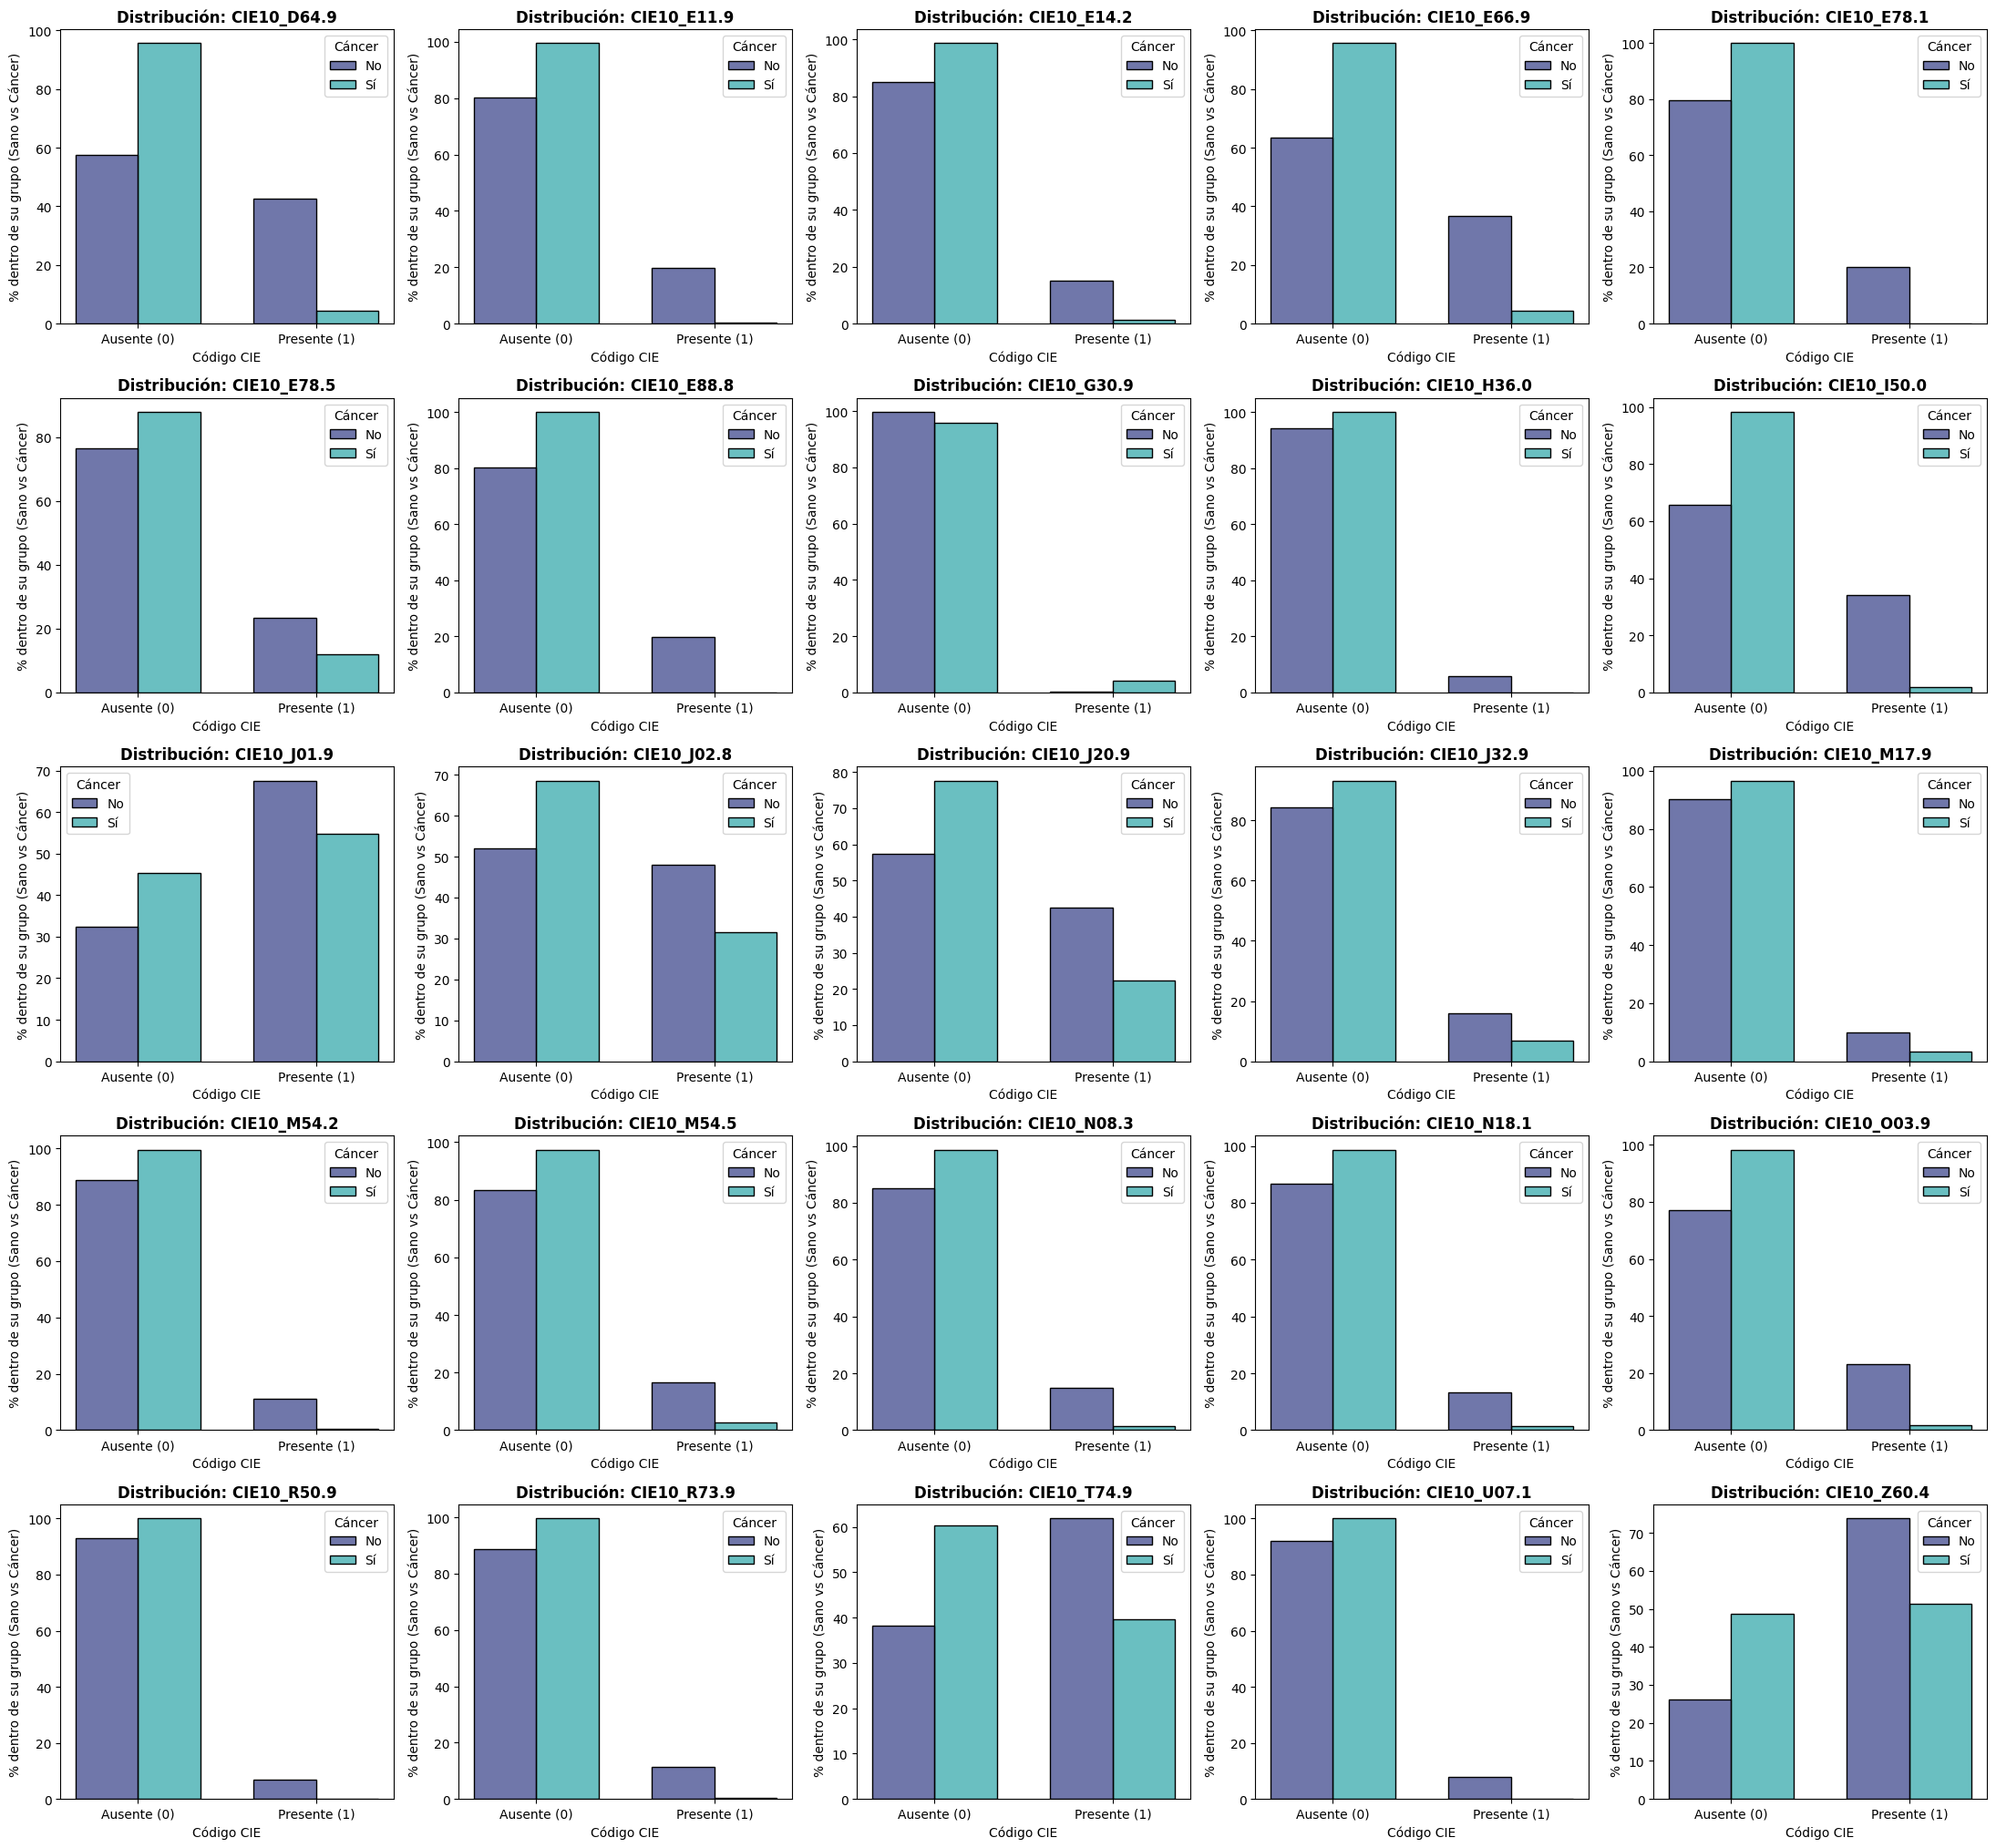

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Crear un dataframe con las variables y la etiqueta de cáncer
data_with_target = X_test_cie_proc.copy()
data_with_target['cancer_pulmon'] = y_test_cie.values
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Aseguramos que la columna objetivo sea entera para evitar problemas de hue
data_with_target['cancer_pulmon'] = data_with_target['cancer_pulmon'].astype(int)

cols = X_test_cie_proc.columns
n_cols = 5
n_rows = (len(cols) // n_cols) + 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    # Usamos histplot con common_norm=False para normalizar por grupo
    sns.histplot(
        data=data_with_target, 
        x=col, 
        hue='cancer_pulmon', 
        multiple="dodge",     # Barras separadas (No/Sí)
        stat="percent",       # Porcentaje
        common_norm=False,    # CADA color suma 100% por separado
        discrete=True,        # Valores discretos (0 y 1)
        palette="mako",
        ax=axes[i],
        shrink=0.7
    )
    
    axes[i].set_title(f"Distribución: {col}", fontsize=12, fontweight='bold')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Ausente (0)', 'Presente (1)'])
    axes[i].set_xlabel("Código CIE")
    axes[i].set_ylabel("% dentro de su grupo (Sano vs Cáncer)")

    # Ajuste dinámico de la leyenda para evitar que se duplique o falle
    if axes[i].get_legend():
        handles = axes[i].get_legend().legend_handles
        axes[i].legend(
            handles=handles, 
            labels=['No', 'Sí'], 
            title='Cáncer'
        )
# Limpiar los subplots sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Lo normal en este tipo de gráficos es que las distribuciones fueran muy parecidas entre cohortes en la mayoría de variables. Esto que vemos, está revelando información clave acerca de los inverosímiles resultados que hemos obtenido hasta ahora en los modelos. 

Todas las variables presentan diferente distribución entre cohortes, de manera que será demasiado fácil para el modelo distinguir quien padece cáncer de quién no.

Todo esto, se puede ver analíticamente mediante el test estadístico de Fisher, este test resuelve el siguiente contraste de hipótesis:

- Hipótesis Nula ($H_0$): $p_1 = p_2$. No hay asociación; la presencia del código CIE es independiente de tener cáncer.
- Hipótesis Alternativa ($H_1$): $p_1 \neq p_2$. Existe asociación; la probabilidad de tener el código CIE difiere significativamente entre pacientes con y sin cáncer.

Si $p_{valor} < 0.05$: El contraste rechaza $H_0$. Existe una relación estadística donde la presencia de ese código CIE específico aumenta las "posibilidades" (odds) de pertenecer al grupo con cáncer. Si $p > 0.05$: No hay evidencia suficiente para rechazar $H_0$, por lo que el código CIE no se considera un diferenciador estadístico para las cohortes.

El $OR$ es la forma de cuantificar la fuerza de esa relación que el test de Fisher declara como significativa o no. Cuando $OR > 1$ la presencia de una enfermedad es un factor de riesgo para padecer cáncer de pulmón y si $OR < 1$ la enfermedad supone un factor protector.

In [21]:
from scipy.stats import fisher_exact
import pandas as pd

def analizar_asociaciones(df, target_col):
    resultados = []
    
    # Iterar por todas las columnas excepto el target
    columnas_cie = [c for c in df.columns if c != target_col]
    
    for col in columnas_cie:
        # 1. Crear tabla de contingencia 2x2
        # Filas: Cáncer (0, 1) | Columnas: Código CIE (0, 1)
        tabla = pd.crosstab(df[target_col], df[col])
        
        # Verificar que la tabla sea 2x2 (a veces falta una categoría si es muy rara)
        if tabla.shape == (2, 2):
            # 2. Calcular Test de Fisher y Odds Ratio
            # odds_ratio = (a*d) / (b*c)
            odds_ratio, p_valor = fisher_exact(tabla)
            
            resultados.append({
                'Variable': col,
                'Odds Ratio': round(odds_ratio, 4),
                'p-valor': round(p_valor, 6),
                'Significativo (p<0.05)': p_valor < 0.05
            })
    
    # Convertir a DataFrame y ordenar por p-valor
    df_res = pd.DataFrame(resultados).sort_values('p-valor')
    return df_res

# Ejecución
df_analisis = analizar_asociaciones(data_with_target, 'cancer_pulmon')

# Ver las 10 variables con mayor asociación estadística
display(df_analisis)

,Variable,Odds Ratio,p-valor,Significativo (p<0.05)
0,CIE10_D64.9,0.0608,0.000000,True
1,CIE10_E11.9,0.0176,0.000000,True
2,CIE10_E14.2,0.0742,0.000000,True
3,CIE10_E66.9,0.0782,0.000000,True
4,CIE10_E78.1,0.0000,0.000000,True
6,CIE10_E88.8,0.0000,0.000000,True
12,CIE10_J20.9,0.3896,0.000000,True
9,CIE10_I50.0,0.0337,0.000000,True
15,CIE10_M54.2,0.0341,0.000000,True
23,CIE10_U07.1,0.0000,0.000000,True


In [22]:
print(f"Todas las variables son significativas" if df_analisis["Significativo (p<0.05)"].all() else "No todas las variables son significativas")

Todas las variables son significativas


### Tablas de contigencia

## Modelado con CV

In [12]:
from funciones import tunear_multiples_modelos, resumen_tuning
from glob import glob

print("=" * 80)
print("BÚSQUEDA DE HIPERPARÁMETROS CON CV - DATOS SIN PROCESAR")
print("=" * 80)

directorio_modelos = "models"
os.makedirs(directorio_modelos, exist_ok=True)

# Buscar modelos guardados previamente
modelos_guardados = glob(os.path.join(directorio_modelos, "mejor_modelo_cie_*.joblib"))

if modelos_guardados:
    print("\n✅ Modelos guardados encontrados:")
    for modelo_path in modelos_guardados:
        print(f"   - {os.path.basename(modelo_path)}")
    
    # Cargar el primer modelo guardado
    ruta_modelo = modelos_guardados[0]
    mejor_modelo_cie = joblib.load(ruta_modelo)
    mejor_modelo_nombre = os.path.basename(ruta_modelo).replace("mejor_modelo_cie_", "").replace(".joblib", "")
    
    print(f"\n✓ Modelo cargado desde: '{ruta_modelo}'")
    print(f"✓ Modelo seleccionado: {mejor_modelo_nombre}")
else:
    print("\n⏳ No hay modelos guardados. Ejecutando búsqueda de hiperparámetros...")
    
    # Tuning con datos CRUDOS + pipeline de preprocesamiento
    resultados_cie = tunear_multiples_modelos(
        modelos=['RandomForest', 'SVM', 'XGBoost', 'MLPClassifier'],
        X_train=X_train_cie,  # Datos SIN procesar
        y_train=y_train_cie,
        preprocessing_pipeline=preprocesamiento_cie,  # Pipeline integrada
        cv=5,
        scoring='f1_weighted'
    )
    
    # Generar resumen comparativo
    resumen = resumen_tuning(resultados_cie)
    
    # Obtener mejor modelo
    if not resumen.empty:
        mejor_modelo_nombre = resumen.iloc[0]['Modelo']
        mejor_modelo_cie = resultados_cie[mejor_modelo_nombre]['mejor_modelo']
        
        print(f"\n✓ Mejor modelo encontrado: {mejor_modelo_nombre}")
        
        # Definir la ruta del archivo y guardar el modelo
        ruta_modelo = os.path.join(directorio_modelos, f"mejor_modelo_cie_{mejor_modelo_nombre.lower()}.joblib")
        joblib.dump(mejor_modelo_cie, ruta_modelo)
        
        print(f"✓ Mejor modelo guardado exitosamente en: '{ruta_modelo}'")
    else:
        print("⚠️ No hay resultados válidos")

# Hacer predicciones (la pipeline está integrada)
print("\n" + "=" * 80)
print("EVALUACIÓN EN TEST")
print("=" * 80)

y_pred_cie = mejor_modelo_cie.predict(X_test_cie)
y_pred_proba_cie = mejor_modelo_cie.predict_proba(X_test_cie)[:, 1]

# Métricas
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

print(f"\nF1-Score: {f1_score(y_test_cie, y_pred_cie, average='weighted'):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_cie, y_pred_proba_cie):.4f}")

print("\n📊 Matriz de confusión:")
print(confusion_matrix(y_test_cie, y_pred_cie))

print("\n📈 Reporte de clasificación:")
print(classification_report(y_test_cie, y_pred_cie, target_names=['Sin cáncer', 'Con cáncer']))

BÚSQUEDA DE HIPERPARÁMETROS CON CV - DATOS SIN PROCESAR

✅ Modelos guardados encontrados:
   - mejor_modelo_cie_svm.joblib

✓ Modelo cargado desde: 'models\mejor_modelo_cie_svm.joblib'
✓ Modelo seleccionado: svm

EVALUACIÓN EN TEST

F1-Score: 0.9360
ROC-AUC: 0.9807

📊 Matriz de confusión:
[[587  26]
 [ 28 204]]

📈 Reporte de clasificación:
              precision    recall  f1-score   support

  Sin cáncer       0.95      0.96      0.96       613
  Con cáncer       0.89      0.88      0.88       232

    accuracy                           0.94       845
   macro avg       0.92      0.92      0.92       845
weighted avg       0.94      0.94      0.94       845



## Reporte de rendimiento


F1-Score: 0.9360
ROC-AUC: 0.9807


C:\Users\rtrin\AppData\Local\Temp\ipykernel_28392\2152771932.py:24: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


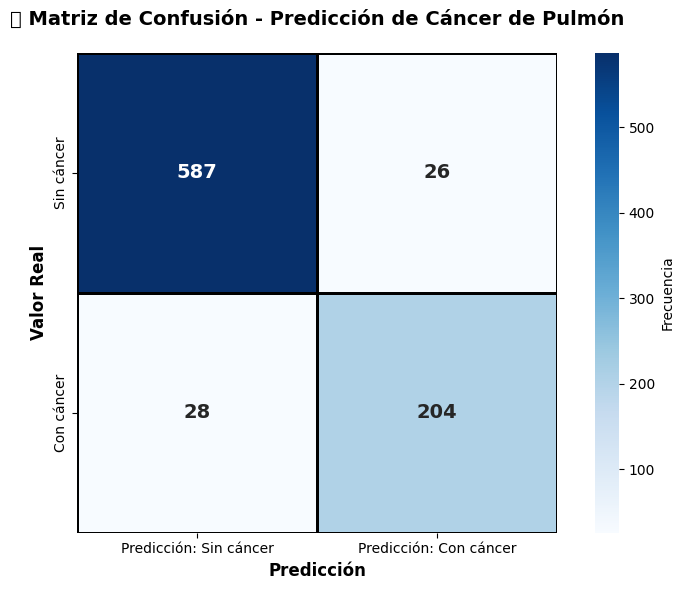


📈 Reporte de clasificación:
              precision    recall  f1-score   support

  Sin cáncer       0.95      0.96      0.96       613
  Con cáncer       0.89      0.88      0.88       232

    accuracy                           0.94       845
   macro avg       0.92      0.92      0.92       845
weighted avg       0.94      0.94      0.94       845



In [13]:
print(f"\nF1-Score: {f1_score(y_test_cie, y_pred_cie, average='weighted'):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_cie, y_pred_proba_cie):.4f}")
    
# 📊 Matriz de confusión con visualización
cm = confusion_matrix(y_test_cie, y_pred_cie)
cm_df = pd.DataFrame(cm, 
                     index=['Sin cáncer', 'Con cáncer'], 
                     columns=['Predicción: Sin cáncer', 'Predicción: Con cáncer'])

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, 
            annot=True, 
            fmt='d', 
            cmap='Blues', 
            cbar_kws={'label': 'Frecuencia'},
            linewidths=2,
            linecolor='black',
            annot_kws={'size': 14, 'weight': 'bold'},
            square=True)
plt.title('📊 Matriz de Confusión - Predicción de Cáncer de Pulmón', 
          fontsize=14, fontweight='bold', pad=20)
plt.ylabel('Valor Real', fontsize=12, fontweight='bold')
plt.xlabel('Predicción', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📈 Reporte de clasificación:")
print(classification_report(y_test_cie, y_pred_cie, target_names=['Sin cáncer', 'Con cáncer']))

📊 Generando gráficas PR-AUC y ROC-AUC para el modelo ganador...
   Modelo: SVM
   ✅ Probabilidades obtenidas
   Threshold 0.50 - PR: Precision=0.8982, Recall=0.8750
   Threshold 0.50 - ROC: FPR=0.0375, TPR=0.8750


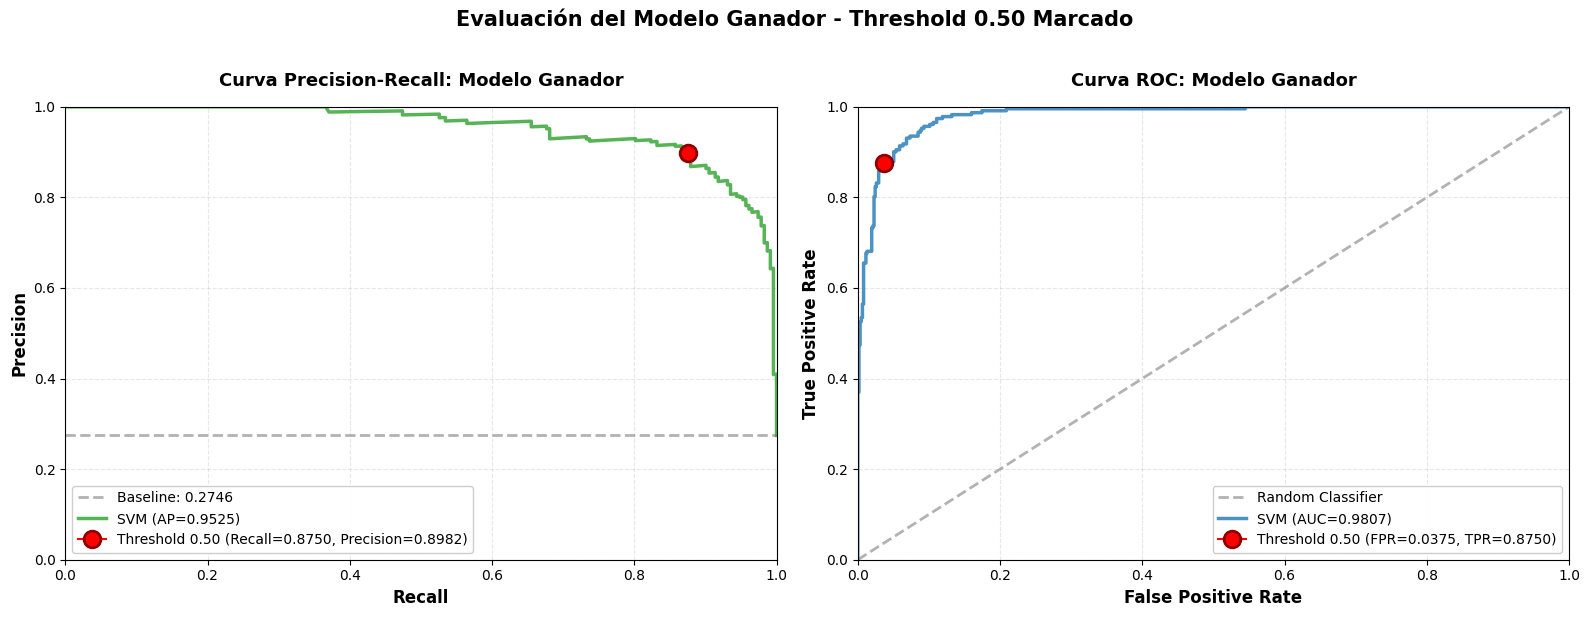


📈 RESUMEN MODELO GANADOR
Modelo: SVM
PR-AUC (Test): 0.9525
ROC-AUC (Test): 0.9807

Métricas en Threshold 0.50:
  - Precision: 0.8982
  - Recall: 0.8750
  - FPR: 0.0375
  - TPR: 0.8750


In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print("📊 Generando gráficas PR-AUC y ROC-AUC para el modelo ganador...")
print(f"   Modelo: {mejor_modelo_nombre}")

# Obtener probabilidades del mejor modelo
def obtener_probabilidades(modelo, X_test):
    try:
        return modelo.predict_proba(X_test)[:, 1]
    except (AttributeError, TypeError):
        try:
            decision = modelo.decision_function(X_test)
            return (decision - decision.min()) / (decision.max() - decision.min())
        except (AttributeError, TypeError):
            try:
                modelo_base = modelo.best_estimator_
                return obtener_probabilidades(modelo_base, X_test)
            except Exception:
                print("   ⚠️  No se pudo obtener probabilidades del modelo.")
                return modelo.predict(X_test).astype(float)

# Calcular métricas - USAR X_test_cie (sin procesar) porque el modelo tiene su propio preprocesador
y_proba = obtener_probabilidades(mejor_modelo_cie, X_test_cie)
precision, recall, pr_thresholds = precision_recall_curve(y_test_cie, y_proba)
fpr, tpr, roc_thresholds = roc_curve(y_test_cie, y_proba)
pr_auc = average_precision_score(y_test_cie, y_proba)
roc_auc = auc(fpr, tpr)

# Encontrar el índice más cercano al threshold de 0.50
idx_pr_threshold = np.argmin(np.abs(pr_thresholds - 0.50))
idx_roc_threshold = np.argmin(np.abs(roc_thresholds - 0.50))

# Obtener valores en el threshold de 0.50
pr_value_at_50 = precision[idx_pr_threshold]
recall_value_at_50 = recall[idx_pr_threshold]
fpr_value_at_50 = fpr[idx_roc_threshold]
tpr_value_at_50 = tpr[idx_roc_threshold]

print(f"   ✅ Probabilidades obtenidas")
print(f"   Threshold 0.50 - PR: Precision={pr_value_at_50:.4f}, Recall={recall_value_at_50:.4f}")
print(f"   Threshold 0.50 - ROC: FPR={fpr_value_at_50:.4f}, TPR={tpr_value_at_50:.4f}")

# Crear las gráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# GRÁFICA 1: PRECISION-RECALL
baseline = np.mean(y_test_cie)
ax1.axhline(y=baseline, color='gray', linestyle='--', lw=2, alpha=0.6, label=f'Baseline: {baseline:.4f}')

ax1.plot(recall, precision,
         label=f'{mejor_modelo_nombre} (AP={pr_auc:.4f})',
         color='#2ca02c',
         linewidth=2.5,
         markersize=5,
         alpha=0.8)

# Marcar el punto del threshold 0.50
ax1.plot(recall_value_at_50, pr_value_at_50, 
         marker='o', markersize=12, color='red', 
         markeredgecolor='darkred', markeredgewidth=2,
         label=f'Threshold 0.50 (Recall={recall_value_at_50:.4f}, Precision={pr_value_at_50:.4f})',
         zorder=5)

ax1.set_xlabel('Recall', fontsize=12, fontweight='bold')
ax1.set_ylabel('Precision', fontsize=12, fontweight='bold')
ax1.set_title('Curva Precision-Recall: Modelo Ganador',
              fontsize=13, fontweight='bold', pad=15)
ax1.legend(fontsize=10, loc='best', framealpha=0.95)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])

# GRÁFICA 2: ROC
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2, alpha=0.6, label='Random Classifier')

ax2.plot(fpr, tpr,
         label=f'{mejor_modelo_nombre} (AUC={roc_auc:.4f})',
         color='#1f77b4',
         linewidth=2.5,
         markersize=5,
         alpha=0.8)

# Marcar el punto del threshold 0.50
ax2.plot(fpr_value_at_50, tpr_value_at_50, 
         marker='o', markersize=12, color='red',
         markeredgecolor='darkred', markeredgewidth=2,
         label=f'Threshold 0.50 (FPR={fpr_value_at_50:.4f}, TPR={tpr_value_at_50:.4f})',
         zorder=5)

ax2.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax2.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax2.set_title('Curva ROC: Modelo Ganador',
              fontsize=13, fontweight='bold', pad=15)
ax2.legend(fontsize=10, loc='lower right', framealpha=0.95)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])

plt.suptitle(f'Evaluación del Modelo Ganador - Threshold 0.50 Marcado',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("📈 RESUMEN MODELO GANADOR")
print("=" * 80)
print(f"Modelo: {mejor_modelo_nombre}")
print(f"PR-AUC (Test): {pr_auc:.4f}")
print(f"ROC-AUC (Test): {roc_auc:.4f}")
print(f"\nMétricas en Threshold 0.50:")
print(f"  - Precision: {pr_value_at_50:.4f}")
print(f"  - Recall: {recall_value_at_50:.4f}")
print(f"  - FPR: {fpr_value_at_50:.4f}")
print(f"  - TPR: {tpr_value_at_50:.4f}")
print("=" * 80)